# ПЗ-6. Численное дифференцирование: битва формул

> 🎮 Перед нами «чёрный ящик»: функция, значения
> которой мы умеем вынимать (иногда — только из таблицы датчиков,
> иногда — с шумом). Нужно достать из ящика **производные** и выяснить,
> какая формула выжимает из ящика больше при тех же усилиях.

| уровень | метка | что это значит |
|---|---|---|
| 🟢 | прогрев | детский сад |
| 🟠 | продвинутая | базовый минимум |
| ★ | звёздочка | альфа |
| ★★ | двойная звёздочка | сигма |

**Как работать.** Условия задач в md-блоках,  `✍️ ДЕЛАЙТЕ` в ячейках. 
После каждой задачи стоит ячейка `✅ Самопроверка`:
она исполняется без ошибок, только если решение верное (и печатает
короткий вердикт). Блоки идут по нарастанию - исполняйте задания в блокноте
сверху вниз.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 110
np.set_printoptions(precision=6)
print('numpy', np.__version__)

numpy 2.5.4


## 📋 Шпаргалка формул

Все прогрессии ошибки — по Тейлору вокруг точки $x_0$, шаг $h$:

| формула | остаток | порядок |
|---|---|---|
| правая $\dfrac{f(x{+}h)-f(x)}{h}$ | $-\tfrac12 h f''(\xi)$ | $O(h)$ |
| левая $\dfrac{f(x)-f(x{-}h)}{h}$ | $+\tfrac12 h f''(\xi)$ | $O(h)$ |
| центральная $\dfrac{f(x{+}h)-f(x{-}h)}{2h}$ | $-\tfrac{h^2}{6}f'''(\xi)$ | $O(h^2)$ |
| краевая слева $\dfrac{-3y_{-1}+4y_0-y_{+1}}{2h}$ | $+\tfrac{h^2}{3}f'''(\xi)$ | $O(h^2)$, вдвое грубее |
| вторая $\dfrac{y_{-1}-2y_0+y_{+1}}{h^2}$ | $\tfrac{h^2}{12}f''''(\xi)$ | $O(h^2)$ |

**Шум и оптимальный шаг.** Если $|\tilde f - f| \le \delta$ (значения
вычисляются с погрешностью $\delta$):

$$\text{правая}: \quad \frac{2\delta}{h} + \frac{M_2}{2}h \ \Rightarrow\
h_* = 2\sqrt{\frac{\delta}{M_2}}, \qquad
\text{центральная}: \quad \frac{\delta}{h} + \frac{M_3}{6}h^2 \ \Rightarrow\
h_* = \Bigl(\frac{3\delta}{M_3}\Bigr)^{1/3}.$$

**Метод неопределённых коэффициентов.** Хотим
$f^{(k)}(x_0)\approx \frac{1}{h^k}\sum_j c_j f(x_0 + u_j h)$ на узлах
$u_j$ (в единицах $h$): требуем равенства на $f = 1, x, x^2, \dots$,
то есть решаем систему

$$\sum_j c_j\,u_j^{\,m} = 0 \ \ (m \ne k), \qquad
\sum_j c_j\,u_j^{\,k} = k!.$$

Подробнее в лекциях, вы ведь следили за преподавателем !!

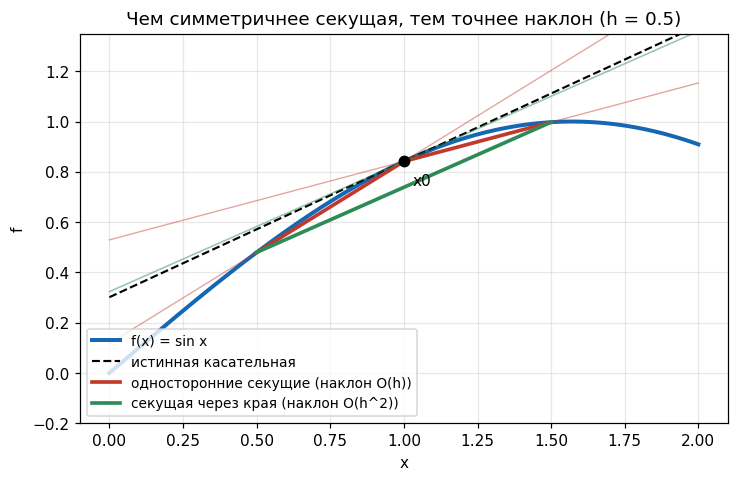

In [2]:
# Геометрия: три секущие против истинной касательной. 
f = lambda x: np.sin(x)
x0, hh = 1.0, 0.5
xs = np.linspace(0.0, 2.0, 300)

ys, yL, yR = f(x0), f(x0 - hh), f(x0 + hh)
fig, ax = plt.subplots(figsize=(7.6, 4.6))
ax.plot(xs, f(xs), lw=2.6, color='#1667b3', label='f(x) = sin x')
ax.plot(xs, ys + np.cos(x0) * (xs - x0), '--k', lw=1.4,
        label='истинная касательная')
ax.plot([x0 - hh, x0], [yL, ys], lw=2.4, color='#c0392b',
        label='односторонние секущие (наклон O(h))')
ax.plot([x0, x0 + hh], [ys, yR], lw=2.4, color='#c0392b')
kl = (ys - yL) / hh
ax.plot(xs, ys + kl * (xs - x0), lw=0.9, color='#c0392b', alpha=0.45)
kr = (yR - ys) / hh
ax.plot(xs, ys + kr * (xs - x0), lw=0.9, color='#c0392b', alpha=0.45)
kc = (yR - yL) / (2 * hh)
ax.plot([x0 - hh, x0 + hh], [yL, yR], lw=2.4, color='#2e8b57',
        label='секущая через края (наклон O(h^2))')
ax.plot(xs, ys + kc * (xs - x0), lw=1.0, color='#2e8b57', alpha=0.5)
ax.scatter([x0], [ys], zorder=5, color='k', s=45)
ax.annotate('x0', (x0, ys), textcoords='offset points', xytext=(6, -16))
ax.set_xlabel('x'); ax.set_ylabel('f')
ax.set_title('Чем симметричнее секущая, тем точнее наклон (h = 0.5)')
ax.set_ylim(-0.2, 1.35)
ax.legend(loc='lower left', fontsize=9)
ax.grid(alpha=0.3)
plt.show()

---
## 🟢 Задача 1. Три формулы и их порядки

Даны две "подопытные" функции:

$$f_1(x) = \sin x \ \ (x_0 = 1.0), \qquad f_2(x) = e^x \ \ (x_0 = 0.5).$$

Точная производная известна аналитически ($f_1' = \cos x$, $f_2' = e^x$),
так что ошибку каждой формулы можно измерить честно.

**Что сделать:**

- **(а)** Реализовать три функции: `left_diff(f, x0, h)`,
  `right_diff(f, x0, h)`, `central_diff(f, x0, h)`.
- **(б)** Для $h = 0.2,\ 0.1,\ 0.05,\ 0.025$ построить таблицу ошибок
  «формула против истины» для обеих подопытных. Убедиться: односторонние
  ошибки падают **в 2 раза** при $h/2$, центральная — **в 4 раза**.
- **(в)** Короткий вывод: почему у центральной секущей порядок выше
  (что делает симметрия с членом $\tfrac{h^2}{2}f''$?).

> 💡 **Подсказка.** Ошибки удобно собирать в список и делить
> попарно: `err[i] / err[i+1]` - это "во сколько раз точнее на
> вдвое меньшем шаге".

In [3]:
# Каркас задачи 1: подопытные и их точные производные
f1, df1, X1 = np.sin, np.cos, 1.0
f2, df2, X2 = np.exp, np.exp, 0.5
print("f1 = sin,  x0 = 1.0,  точная f1'(1) =", f"{np.cos(X1):.12f}")
print("f2 = exp,  x0 = 0.5,  точная f2'(0.5) =", f"{df2(X2):.12f}")
print('шаги для таблицы порядков: h = 0.2, 0.1, 0.05, 0.025')
print("(правила из задания: односторонние /2, центральная /4 — проверьте!)")

f1 = sin,  x0 = 1.0,  точная f1'(1) = 0.540302305868
f2 = exp,  x0 = 0.5,  точная f2'(0.5) = 1.648721270700
шаги для таблицы порядков: h = 0.2, 0.1, 0.05, 0.025
(правила из задания: односторонние /2, центральная /4 — проверьте!)


In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 1
# TODO (а): left_diff / right_diff / central_diff(f, x0, h)
# TODO (б): таблица ошибок по h = 0.2, 0.1, 0.05, 0.025 для обеих функций
# TODO (в): краткий вывод (можно просто печатными строками)


In [ ]:
# ✅ Самопроверка задачи 1
import numpy as np
fA = lambda t: np.sin(t); dfA = np.cos
fB = lambda t: np.exp(t); dfB = np.exp
assert abs(central_diff(fA, 1.0, 0.2) - dfA(1.0)) < 1e-2, 'центральная должна считать sin'
assert abs(central_diff(fB, 0.5, 0.2) - dfB(0.5)) < 1e-1, 'центральная должна считать exp'
eL = abs(left_diff(fA, 1.0, 0.4) - dfA(1.0))
eR = abs(right_diff(fA, 1.0, 0.4) - dfA(1.0))
eC = abs(central_diff(fA, 1.0, 0.4) - dfA(1.0))
assert eC < eL / 3 and eC < eR / 3, (
    f"при h=0.4 центральная должна быть заметно точнее: {eC:.2e} vs {eL:.2e}/{eR:.2e}")
r1 = abs(central_diff(fA, 1.0, 0.2) - dfA(1.0)) / abs(central_diff(fA, 1.0, 0.1) - dfA(1.0))
r2 = abs(central_diff(fB, 0.5, 0.2) - dfB(0.5)) / abs(central_diff(fB, 0.5, 0.1) - dfB(0.5))
assert 2.6 < r1 < 5.5 and 2.6 < r2 < 5.5, (
    f"ошибка при h/2 должна падать ~в 4 раза, а получено {r1:.1f}, {r2:.1f}")
print(f"✅ Задача 1 ок: центральная падает {r1:.2f}x / {r2:.2f}x (теория: 4x)")

---
## 🟢 Задача 2. Траектория из таблицы: скорость и ускорение

Датчик положения выдаёт таблицу $S(t) = (s(t_i))$; саму функцию
не знаем - есть только числа. Шаг $h = 0.125$, узлов 17.

Из шпаргалки:

- скорость: центральная формула для внутренних узлов;
- у краёв: **краевая** формула
  $\dfrac{-3s_0 + 4s_1 - s_2}{2h}$ (и зеркальная справа);
- ускорение: вторая центральная разность
  $\dfrac{s_{i-1} - 2 s_i + s_{i+1}}{h^2}$.

**Что сделать:**

- **(а)** По таблице $S$ вычислить скорости в **всех** узлах
  (внутренние - центральной, края - краевыми) и собрать в массив
  `v_c` той же длины, что временная сетка.
- **(б)** Аналогично ускорения `a_c` (края разрешается оставить `np.nan`).
- **(в)** Напечатать максимальную ошибку каждой оценки. Приятный
  сюрприз ждёт вторую разность: среди кубических траекторий она
  ведёт себя лучше, чем обещает её порядок.

> 🧪 **Правило честности:** в расчётах используем **только** массив
> `S` (истинная формула движения нужна лишь для контроля ошибок).

t    :  0.000  0.125  0.250  0.375  0.500  0.625  0.750  0.875  1.000  1.125  1.250  1.375  1.500  1.625  1.750  1.875  2.000
s(t) :  1.200  1.437  1.606  1.723  1.800  1.852  1.894  1.938  2.000  2.093  2.231  2.429  2.700  3.059  3.519  4.095  4.800
(для контроля: v = 2.2 - 5.2t + 3.6t^2,  a = -5.2 + 7.2t)


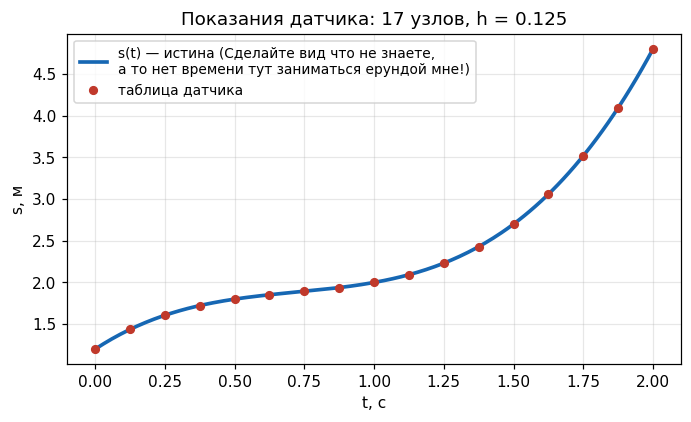

In [7]:
# Каркас задачи 2: таблица-датчик
s_true = lambda t: 1.2 + 2.2*t - 2.6*t**2 + 1.2*t**3
H2 = 0.125
T = np.arange(0.0, 2.0 + H2/2, H2)
S = s_true(T)
print('t    :', ' '.join(f'{t:6.3f}' for t in T))
print('s(t) :', ' '.join(f'{s:6.3f}' for s in S))
print('(для контроля: v = 2.2 - 5.2t + 3.6t^2,  a = -5.2 + 7.2t)')

fig, ax = plt.subplots(figsize=(7.2, 3.9))
tt = np.linspace(0, 2, 200)
ax.plot(tt, s_true(tt), lw=2.4, color='#1667b3', label='s(t) — истина (Сделайте вид что не знаете,\nа то нет времени тут заниматься ерундой мне!)')
ax.plot(T, S, 'o', ms=5, color='#c0392b', label='таблица датчика')
ax.set_xlabel('t, с'); ax.set_ylabel('s, м')
ax.set_title('Показания датчика: 17 узлов, h = 0.125')
ax.legend(fontsize=9, loc='upper left'); ax.grid(alpha=0.3)
plt.show()

In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 2
# TODO (а): массив v_c (17 чисел): внутренние — центральная формула,
#            края — краевые формулы (слева и справа)
# TODO (б): массив a_c второй центральной разностью (края = np.nan)
# TODO (в): максимальные ошибки против «истины» — только для отчёта


In [ ]:
# ✅ Самопроверка задачи 2
import numpy as np
v_true = 2.2 - 5.2*T + 3.6*T**2
a_true = -5.2 + 7.2*T
assert v_c.shape == T.shape, 'массив v_c должен быть той же длины, что сетка'
assert not np.any(np.isnan(v_c)), 'краевые узлы скорости надо заполнить краевыми формулами'
err_v = np.abs(v_c - v_true)
err_a = np.abs(a_c[1:-1] - a_true[1:-1])
assert err_v[1:-1].max() < 0.028, f"центральные скорости: {err_v[1:-1].max():.3f} > M3*h^2/6"
assert err_v[0] < 0.06 and err_v[-1] < 0.06, f"краевые скорости: {max(err_v[0], err_v[-1]):.3f}"
assert err_a.max() < 1e-9, (
    f"вторая разность должна быть ТОЧНА на кубике (max err {err_a.max():.2e})")
print(f"✅ Задача 2 ок: скорость max err {err_v.max():.4f}; ускорение точно на кубике "
      f"({err_a.max():.1e})")

---
## 🟠 Задача 3. $U$-кривая и оптимальный шаг: эксперимент против теории

Теперь у значений функции появляется **шум**. Работаем со следующей моделью:

$$\tilde f(x) = e^x + \delta\,\varepsilon(x), \qquad
\delta = 10^{-4}, \quad |\varepsilon| \le 1,$$

в точке $x_0 = 1$ (там $M_2 \approx M_3 \approx e^{1.05}$). Теория
обещает минимум полной ошибки на

$$h_*^{\text{правая}} = 2\sqrt{\delta/M_2}, \qquad
h_*^{\text{центральная}} = (3\delta/M_3)^{1/3}.$$

**Что сделать:**

- **(а)** По сетке `HS` из каркаса задачи построить кривые ошибки
  $|\,\hat f'(x_0) - e\,|$ для правой и центральной формул на
  $\tilde f$ (зависимость ошибки в точке от шага h); нарисовать обе кривые в $\log$-$\log$ масштабе и отметить
  вертикальными пунктирами теоретические $h_*$.
- **(б)** Найти экспериментальные оптимумы: `h_found_f` (правая) и
  `h_found_c` (центральная) - шаг с минимальной ошибкой на своей кривой.
- **(в)** Итог: совпали ли оптимумы с теорией в
  пределах "порядка"? Почему у центральной "дно" ниже (шум входит как
  $\delta/h$, а не $2\delta/h$)?

In [11]:
# Каркас задачи 3: шум, сетка шагов и теоретические оптимумы
DELTA = 1e-4
f_tilde = lambda x: np.exp(x) + DELTA * np.sin(1997.0 * x)   # |f_tilde - f| <= DELTA
X03 = 1.0
M_E = float(np.exp(1.05))        # M2 ~ M3 ~ e^{1.05} на отрезке x0 ± h
HS = np.logspace(0.0, -8.0, 90)
H_STAR_F = 2 * np.sqrt(DELTA / M_E)
H_STAR_C = (3 * DELTA / M_E) ** (1.0 / 3.0)
EXACT = float(np.exp(X03))
print(f"delta = {DELTA:g},  M2 = M3 = {M_E:.4f}")
print(f"теория: h* (правая) = {H_STAR_F:.5f},  h* (центральная) = {H_STAR_C:.5f}")
print('сетка HS: от 1.0 до 1e-8, 90 точек')

delta = 0.0001,  M2 = M3 = 2.8577
теория: h* (правая) = 0.01183,  h* (центральная) = 0.04717
сетка HS: от 1.0 до 1e-8, 90 точек


In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 3
# TODO (а): err_f[i], err_c[i] для каждого HS[i] (обе формулы на f_tilde)
#           и loglog-график кривых + вертикальные пунктиры H_STAR_F, H_STAR_C
# TODO (б): h_found_f = HS[argmin(err_f)], h_found_c = HS[argmin(err_c)], печать
# TODO (в): вывод


In [ ]:
# ✅ Самопроверка задачи 3
import numpy as np
rf = h_found_f / H_STAR_F
rc = h_found_c / H_STAR_C
assert 0.2 < rf < 5.0, f"оптимум правой далеко от теории: {rf:.2f} × h*"
assert 0.2 < rc < 5.0, f"оптимум центральной далеко от теории: {rc:.2f} × h*"
print(f"✅ Задача 3 ок: h_found_f = {h_found_f:.4f} ({rf:.2f}×h*), "
      f"h_found_c = {h_found_c:.4f} ({rc:.2f}×h*)")

---
## 🟠 Задача 4. Пять узлов для второй производной

Центральная вторая разность $O(h^2)$ - не предел. Соберём формулу
точнее **методом неопределённых коэффициентов**: ищем

$$f''(x_0) \approx \frac{1}{h^2}\sum_{j=-2}^{2} c_j\, f(x_0 + jh).$$

Требуя точности на $1, x, x^2, x^3, x^4$, получаем систему

$$\sum_j c_j\, j^m = 0 \ (m = 0,1,3,4), \qquad \sum_j c_j\, j^2 = 2.$$

**Что сделать:**

- **(а)** Собрать матрицу коэффициентов (столбцы - степени $m = 0..4$,
  строки - узлы $j = -2..2$) и решить систему `np.linalg.solve`;
  веса сохранить в вектор `w5` (порядок $j=-2..2$).
- **(б)** Реализовать `f2_5(f, x0, h)` и проверить на $x^4$
  (должна быть **точна**) и на $x^5$ (**тоже точна** — проверьте!).
- **(в)** Тест порядка: для $f = \sin$ ошибка должна падать **в 16 раз**
  при $h/2$ (порядок 4). Сравните с центральной формулой $O(h^2)$.

> 💡 Веса в «классике»: $(-1,\ 16,\ -30,\ 16,\ -1)/12$ - но их надо
> вывести решением системы, а не скопировать.

In [13]:
# Каркас задачи 4: узлы и контрольные многочлены
U5 = np.array([-2.0, -1.0, 0.0, 1.0, 2.0])       # узлы в единицах h
print('узлы u_j:', U5)
print('условия: sum c_j * u_j^m = 0 при m = 0,1,3,4;  sum c_j * u_j^2 = 2')
P4 = lambda x: x**4
P5 = lambda x: x**5
P6 = lambda x: x**6
XS4, H4 = 0.7, 0.15
print(f"контрольные многочлены x^4, x^5, x^6 в точке x0 = {XS4}, h = {H4}")
print("точные f''(x0): 12*x0^2 (x^4), 20*x0^3 (x^5); на x^6 впервые рождается ошибка")
print('ожидалось: первые две — точны, на x^6 — впервые родится ошибка')

узлы u_j: [-2. -1.  0.  1.  2.]
условия: sum c_j * u_j^m = 0 при m = 0,1,3,4;  sum c_j * u_j^2 = 2
контрольные многочлены x^4, x^5, x^6 в точке x0 = 0.7, h = 0.15
точные f''(x0): 12*x0^2 (x^4), 20*x0^3 (x^5); на x^6 впервые рождается ошибка
ожидалось: первые две — точны, на x^6 — впервые родится ошибка


In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 4
# TODO (а): матрица V[j, m] = u_j^m (строки — узлы, столбцы — степени);
#            уравнения ставятся на МОМЕНТЫ sum_j c_j*u_j^m -> подумайте про V.T;
#            правая часть [0, 0, 2, 0, 0]; решите -> w5
# TODO (б): def f2_5(f, x0, h): ...  — проверки точности на x^4 и x^5
# TODO (в): тест порядка 4 на f = sin (ошибка /16 при h/2)


In [ ]:
# ✅ Самопроверка задачи 4
import numpy as np
classic = np.array([-1.0/12, 4.0/3, -2.5, 4.0/3, -1.0/12])
assert np.allclose(w5, classic, atol=1e-10), f"веса должны совпасть с классикой, вышло {w5}"
e4 = abs(f2_5(P4, XS4, H4) - 12.0 * XS4 ** 2)
e5 = abs(f2_5(P5, XS4, H4) - 20.0 * XS4 ** 3)
e6 = abs(f2_5(P6, XS4, H4) - 30.0 * XS4 ** 4)
assert e4 < 1e-9, f"x^4: должна быть точна (err {e4:.2e})"
assert e5 < 1e-9, f"x^5: тоже точна (err {e5:.2e})"
assert e6 > 0.002, f"x^6: уже НЕ точна (err {e6:.3f}) — так и должно быть"
eh1 = abs(f2_5(np.sin, 1.0, 0.3) + np.sin(1.0))
eh2 = abs(f2_5(np.sin, 1.0, 0.15) + np.sin(1.0))
ratio = eh1 / eh2
assert 9.0 < ratio < 23.0, f"порядок 4: ошибка должна падать ~16x, получено {ratio:.1f}x"
print(f"✅ Задача 4 ок: x^4/x^5 точны ({e4:.1e}, {e5:.1e}), x^6 err={e6:.3f}, "
      f"порядок {ratio:.1f}x")

---
## ★ Задача 5. Односторонние формулы на четыре узла

Краю сетки позволено больше, чем кажется. По узлам $u_j = 0, 1, 2, 3$
(в единицах $h$) тем же методом постройте:

$$\text{(а)}\quad f'(x_0) \approx \frac{1}{h}\sum_{j=0}^{3} c_j f(x_0 + jh)
\quad\text{с точностью } O(h^3),$$

$$\text{(б)}\quad f''(x_0) \approx \frac{1}{h^2}\sum_{j=0}^{3} d_j f(x_0 + jh)
\quad\text{с точностью } O(h^2).$$

**Что сделать:**

- **(а)** Решить две системы (условия на $1, x, x^2, x^3$; для $f''$
  правая часть равна 2 при $m=2$); веса - в `w_f` и `w_dd`.
- **(б)** Реализовать `d3f(f, x0, h)` и `d2f_edge(f, x0, h)`;
  проверить, что обе **точно** воспроизводят производные на $x^3$.
- **(в)** Для $f = e^x$ при $h = 0.1$ напечатать ошибки обеих формул.

> 🎁 Эта задача - ключ к краевым ускорениям в задаче 2: по желанию
> доделайте края `a_c` через `d2f_edge` и сравните ошибки.

In [14]:
# Каркас задачи 5: узлы и системы
U4 = np.array([0.0, 1.0, 2.0, 3.0])
print('узлы u_j:', U4)
print("f'  : sum c_j u_j^m = 0 при m != 1;  sum c_j u_j = 1  ->  O(h^3)")
print("f'' : sum d_j u_j^m = 0 при m != 2;  sum d_j u_j^2 = 2  ->  O(h^2)")
print('контроль: точность обеих формул на x^3; ошибки на e^x при h = 0.1')

узлы u_j: [0. 1. 2. 3.]
f'  : sum c_j u_j^m = 0 при m != 1;  sum c_j u_j = 1  ->  O(h^3)
f'' : sum d_j u_j^m = 0 при m != 2;  sum d_j u_j^2 = 2  ->  O(h^2)
контроль: точность обеих формул на x^3; ошибки на e^x при h = 0.1


In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 5 (звёздочки!)
# TODO (а): w_f и w_dd через np.linalg.solve
# TODO (б): def d3f(f, x0, h) и def d2f_edge(f, x0, h) + проверки на x^3
# TODO (в): ошибки на e^x при h = 0.1


In [ ]:
# ✅ Самопроверка задачи 5
import numpy as np
wf_ref = np.array([-11.0/6, 3.0, -1.5, 1.0/3])
wdd_ref = np.array([2.0, -5.0, 4.0, -1.0])
assert np.allclose(w_f, wf_ref, atol=1e-9), f"веса f': {w_f}"
assert np.allclose(w_dd, wdd_ref, atol=1e-9), f"веса f'': {w_dd}"
e3 = abs(d3f(lambda t: t**3, 0.2, 0.1) - 3 * 0.04)
e3b = abs(d2f_edge(lambda t: t**3, 0.2, 0.1) - 6 * 0.2)
assert e3 < 1e-10 and e3b < 1e-10, f"на x^3 обе формулы точны: {e3:.2e}, {e3b:.2e}"
e1 = abs(d3f(np.exp, 0.3, 0.1) - np.exp(0.3))
e2 = abs(d2f_edge(np.exp, 0.3, 0.1) - np.exp(0.3))
assert e1 < 2.2e-3, f"d3f на e^x: {e1:.2e} (теория ~ h^3*|f''''|/4)"
assert e2 < 0.062, f"d2f_edge на e^x: {e2:.2e} (теория ~ (11/12)h^2|f''''|)"
print(f"✅ Задача 5 ок: точны на x^3 ({e3:.1e}, {e3b:.1e}); на e^x {e1:.2e} / {e2:.2e}")

---
## ★★ Задача 6. Финальный вызов: телеметрия зонда

Спускаемый зонд передаёт высоту $s$ с шумом $|\eta| \le \delta = 5\cdot10^{-3}$ м
на сетке $h = 0.05$ (101 узел, $t \in [0,5]$). Данные - в каркасе.

**Миссия:**

- **(а)** Восстановить скорость зонда `v_est` во внутренних узлах
  центральной формулой; нарисовать сравнение с baseline, которая в
  скаффолде подписана (она вам НЕ нужна для вычисления - только для
  контроля).
- **(б)** Найти момент `crash_time`, когда показание высоты впервые
  опустилось **ниже 1 м** - по таблице `S_NOISY` (сканирование).
- **(в)** В этом узле оценить скорость `crash_speed` из своего `v_est`
  и напечатать «прогноз посадки».

> 🚨 Почему у краевой скорости (первый узел)
> шум даёт ошибку вдвое большую, чем у центральной, при том же $\delta$?
> И почему усреднение (Ричардсон по $h$ и $2h$) сгладило бы кривую,
> но не изменило бы ответ о моменте касания?

первые 8 показаний (t, s):
   t = 0.00   s =   9.0013
   t = 0.05   s =   8.9031
   t = 0.10   s =   8.7993
   t = 0.15   s =   8.6895
   t = 0.20   s =   8.5844
   t = 0.25   s =   8.4826
   t = 0.30   s =   8.3648
   t = 0.35   s =   8.2623


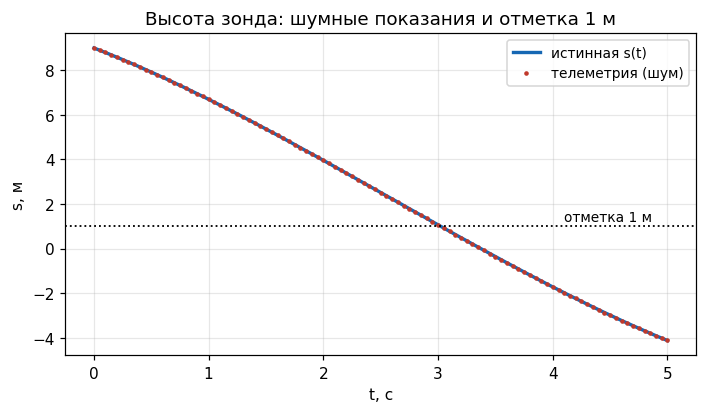

In [15]:
# Каркас задачи 6: телеметрия с шумом
RNG = np.random.default_rng(7)
DELTA6 = 5e-3
s_model = lambda t: 9.0 - 2.0*t - 0.35*t**2 + 0.045*t**3
v_model = lambda t: -2.0 - 0.7*t + 0.135*t**2
T6 = np.linspace(0.0, 5.0, 101)
H6 = T6[1] - T6[0]
S_NOISY = s_model(T6) + RNG.uniform(-DELTA6, DELTA6, T6.size)
print('первые 8 показаний (t, s):')
for t, s in zip(T6[:8], S_NOISY[:8]):
    print(f'   t = {t:.2f}   s = {s:8.4f}')
fig, ax = plt.subplots(figsize=(7.4, 3.8))
tt = np.linspace(0, 5, 200)
ax.plot(tt, s_model(tt), lw=2.2, color='#1667b3', label='истинная s(t)')
ax.plot(T6, S_NOISY, '.', ms=4, color='#c0392b', label='телеметрия (шум)')
ax.axhline(1.0, color='k', ls=':', lw=1.2)
ax.text(4.1, 1.25, 'отметка 1 м', fontsize=9)
ax.set_xlabel('t, с'); ax.set_ylabel('s, м')
ax.set_title('Высота зонда: шумные показания и отметка 1 м')
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.show()

In [ ]:
# ✍️ ДЕЛАЙТЕ — Задача 6 (финал!)
# TODO (а): массив v_est (внутренние узлы, центральная формула) + график
# TODO (б): crash_time — первый узел, где S_NOISY ниже 1.0 (скан таблицы)
# TODO (в): crash_speed = v_est в ближайшем узле к crash_time; печать прогноза


In [ ]:
# ✅ Самопроверка задачи 6
import numpy as np
roots = np.roots([0.045, -0.35, -2.0, 8.0])
t_true = min(float(r.real) for r in roots
             if abs(r.imag) < 1e-9 and 2.4 < r.real < 4.0)
v_true_here = float(v_model(t_true))
dt = abs(crash_time - t_true)
assert dt < 0.3, f"момент касания 1 м: вышло {crash_time:.3f}, истинно {t_true:.3f}"
assert crash_speed < -1.4, f"зонд должен падать: скорость {crash_speed} м/с выглядит неверно"
assert abs(crash_speed - v_true_here) < 0.4, (
    f"скорость у отметки: вышло {crash_speed:.3f}, истинно {v_true_here:.3f}")
print(f"✅ Задача 6 ок: касание 1 м в t* = {crash_time:.2f} с "
      f"(истинно {t_true:.2f}), скорость {crash_speed:.2f} м/с "
      f"(истинно {v_true_here:.2f})")